### **ALL THE LIBRARIES THAT WE ARE USING IN MLR!!!!!!**

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [6]:
df = pd.read_csv("/content/homeprices.csv")
df

,area,bedrooms,age,price
0,2600,3.0,20,550000
1,3000,4.0,15,565000
2,3200,NaN,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000
5,4100,6.0,8,810000


## PERFORMING EDA!!!

In [7]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   area      6 non-null      int64  
 1   bedrooms  5 non-null      float64
 2   age       6 non-null      int64  
 3   price     6 non-null      int64  
dtypes: float64(1), int64(3)
memory usage: 324.0 bytes


In [8]:
df.columns


Index(['area', 'bedrooms', 'age', 'price'], dtype='object')

In [9]:
df["bedrooms"].unique()

array([ 3.,  4., nan,  5.,  6.])

In [10]:
df['bedrooms'].median()

4.0

In [11]:
df['bedrooms'] = df['bedrooms'].fillna(df.bedrooms.median())
df

,area,bedrooms,age,price
0,2600,3.0,20,550000
1,3000,4.0,15,565000
2,3200,4.0,18,610000
3,3600,3.0,30,595000
4,4000,5.0,8,760000
5,4100,6.0,8,810000


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   area      6 non-null      int64  
 1   bedrooms  6 non-null      float64
 2   age       6 non-null      int64  
 3   price     6 non-null      int64  
dtypes: float64(1), int64(3)
memory usage: 324.0 bytes


In [13]:
X = df.drop(columns=['price'])
X

,area,bedrooms,age
0,2600,3.0,20
1,3000,4.0,15
2,3200,4.0,18
3,3600,3.0,30
4,4000,5.0,8
5,4100,6.0,8


In [14]:
y = df['price']
y

,price
0,550000
1,565000
2,610000
3,595000
4,760000
5,810000


In [18]:
#spiling data
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=0)

In [20]:
X_train

,area,bedrooms,age
1,3000,4.0,15
3,3600,3.0,30
0,2600,3.0,20
4,4000,5.0,8


In [21]:
X_test

,area,bedrooms,age
5,4100,6.0,8
2,3200,4.0,18


In [22]:
y_train

,price
1,565000
3,595000
0,550000
4,760000


In [23]:
y_test

,price
5,810000
2,610000


In [24]:
#model
model = LinearRegression()

In [25]:
#model fitting on data
model.fit(x_train,y_train)

LinearRegression()

In [26]:
#model prediction checking
y_pred = model.predict(x_test)
y_pred

array([608500., 554875.])

In [27]:
#dataframe form
pd.DataFrame({'y_test':y_test,'y_predict':y_pred})

,y_test,y_predict
5,810000,608500.0
2,610000,554875.0


In [29]:
#with MAE
pd.DataFrame({'y_test':y_test,'y_predict':y_pred,"MAE":abs(y_test-y_pred)})

,y_test,y_predict,MAE
5,810000,608500.0,201500.0
2,610000,554875.0,55125.0


In [30]:
#testing our model prediction on these inputs
#3000 sqr ft area, 3 bedrooms, 40 year old
# 2500 sqr ft area, 4 bedrooms, 5 year old
print(model.predict([[3000,3,40]]))
print(model.predict([[2500,4,5]]))

[262000.]
[638125.]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


# **Model intercept and slope, make an equation**


In [34]:
#slope
print(model.coef_)

[    236.25 -175125.    -19125.  ]


In [32]:
model.intercept_

np.float64(843624.999999999)

In [38]:
# Y = m1 * X1 + m2 * X2 + m3 * X3 + c (m1,m2,m3 is coefficient and c is intercept)
112.06244194*3000 + 23388.88007794*3 + -3231.71790863*40 + 221323.00186540384


498408.25157402386

In [39]:
print("MSE:",mean_squared_error(y_test,y_pred))
print("R2 Score: ",r2_score(y_test,y_pred))
print("RMSE:",np.sqrt(mean_squared_error(y_test,y_pred)))

MSE: 21820507812.499905
R2 Score:  -1.1820507812499903
RMSE: 147717.66249335217


## **Plot Model on Train and Test data**

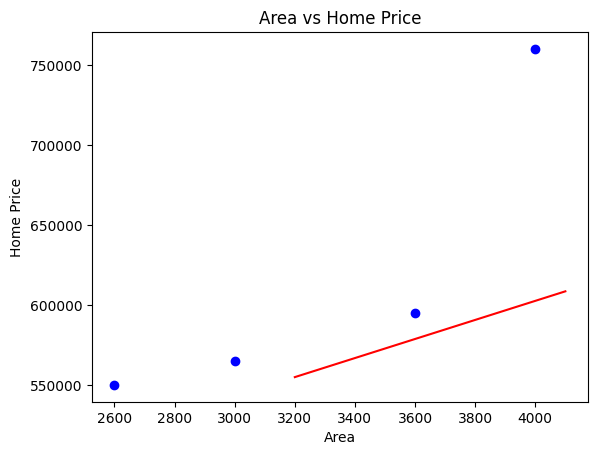

In [51]:
#on  a train data
plt.scatter(X_train['area'], y_train, color='blue')
plt.plot(X_test['area'], y_pred, color='red')
plt.title("Area vs Home Price")
plt.xlabel("Area")
plt.ylabel("Home Price")
plt.show()

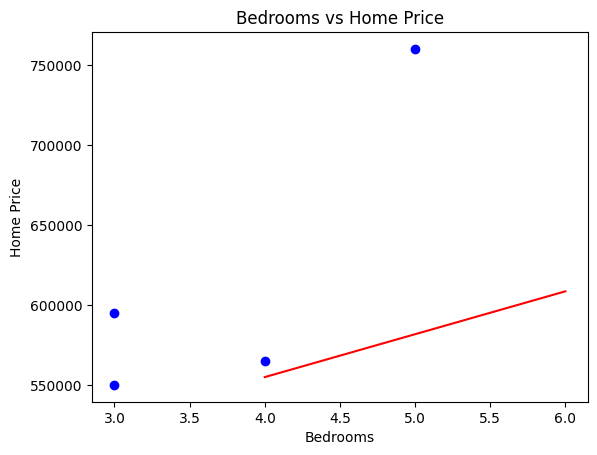

In [45]:
plt.scatter(X_train['bedrooms'], y_train, color='blue')
plt.plot(X_test['bedrooms'], y_pred, color='red')
plt.title("Bedrooms vs Home Price")
plt.xlabel("Bedrooms")
plt.ylabel("Home Price")
plt.show()

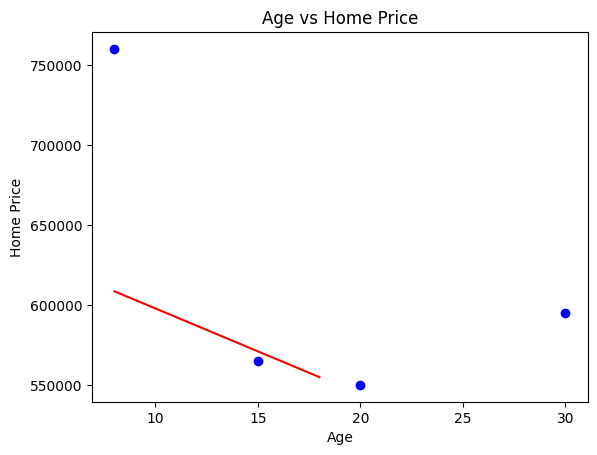

In [47]:
plt.scatter(X_train['age'], y_train, color='blue')
plt.plot(X_test['age'], y_pred, color='red')
plt.title("Age vs Home Price")
plt.xlabel("Age")
plt.ylabel("Home Price")
plt.show()